# 1. Load and display raw particles and noise

Use the project `.venv` kernel. Run section 1, then either method section. Only `tam_dimer_tetramer/batch_0_restacked.mrc`, its STAR metadata, and `noise_restacked.mrc` are used. Select 2,000 particles in STAR order and load all noise images. Preview a small subset; keep original pixels and metadata for both methods.

Long implementation helpers live in [latent_methods.py](latent_methods.py). The notebook contains settings, execution, and comparisons. No output files are written automatically.


In [4]:
# If needed: %pip install mrcfile starfile numpy pandas matplotlib scikit-learn threadpoolctl "aspire==0.14.3"
from pathlib import Path
from time import perf_counter
import sys
import numpy as np
import pandas as pd
import starfile
from IPython.display import display
from threadpoolctl import threadpool_limits

working_directory = Path.cwd().resolve()
project_root = next((p for p in (working_directory, *working_directory.parents)
                     if (p / "LatentSpace_data").is_dir()), None)
if project_root is None:
    raise FileNotFoundError("Cannot find LatentSpace_data")
module_directory = str(project_root / "LatentSpace")
if module_directory not in sys.path:
    sys.path.insert(0, module_directory)
from latent_methods import load_raw_dataset, show_raw, show_pairs

data_root = project_root / "LatentSpace_data"
particle_path = data_root / "tam_dimer_tetramer" / "batch_0_restacked.mrc"
star_path = data_root / "tam_dimer_tetramer" / "J599_split_0_exported.star"
noise_path = data_root / "noise_restacked.mrc"
stack_reference = "J598/restack/batch_0_restacked.mrc"
particle_count = 2000
preview_count = 4

raw_images, image_metadata = load_raw_dataset(
    star_path, particle_path, stack_reference, noise_path, particle_count=particle_count,
)
particle_images = raw_images[:particle_count]  # Views; avoid extra full-stack copies.
noise_images = raw_images[particle_count:]
particle_metadata = image_metadata.iloc[:particle_count].reset_index(drop=True)
particle_names = particle_metadata["rlnImageName"].tolist()
optics = starfile.read(star_path, always_dict=True)["optics"]
print(f"Particles: {particle_images.shape}; noise: {noise_images.shape}")
print(f"Raw images in RAM: {raw_images.nbytes / 1024**2:.1f} MiB")


Particles: (2000, 256, 256); noise: (1314, 256, 256)
Raw images in RAM: 828.5 MiB


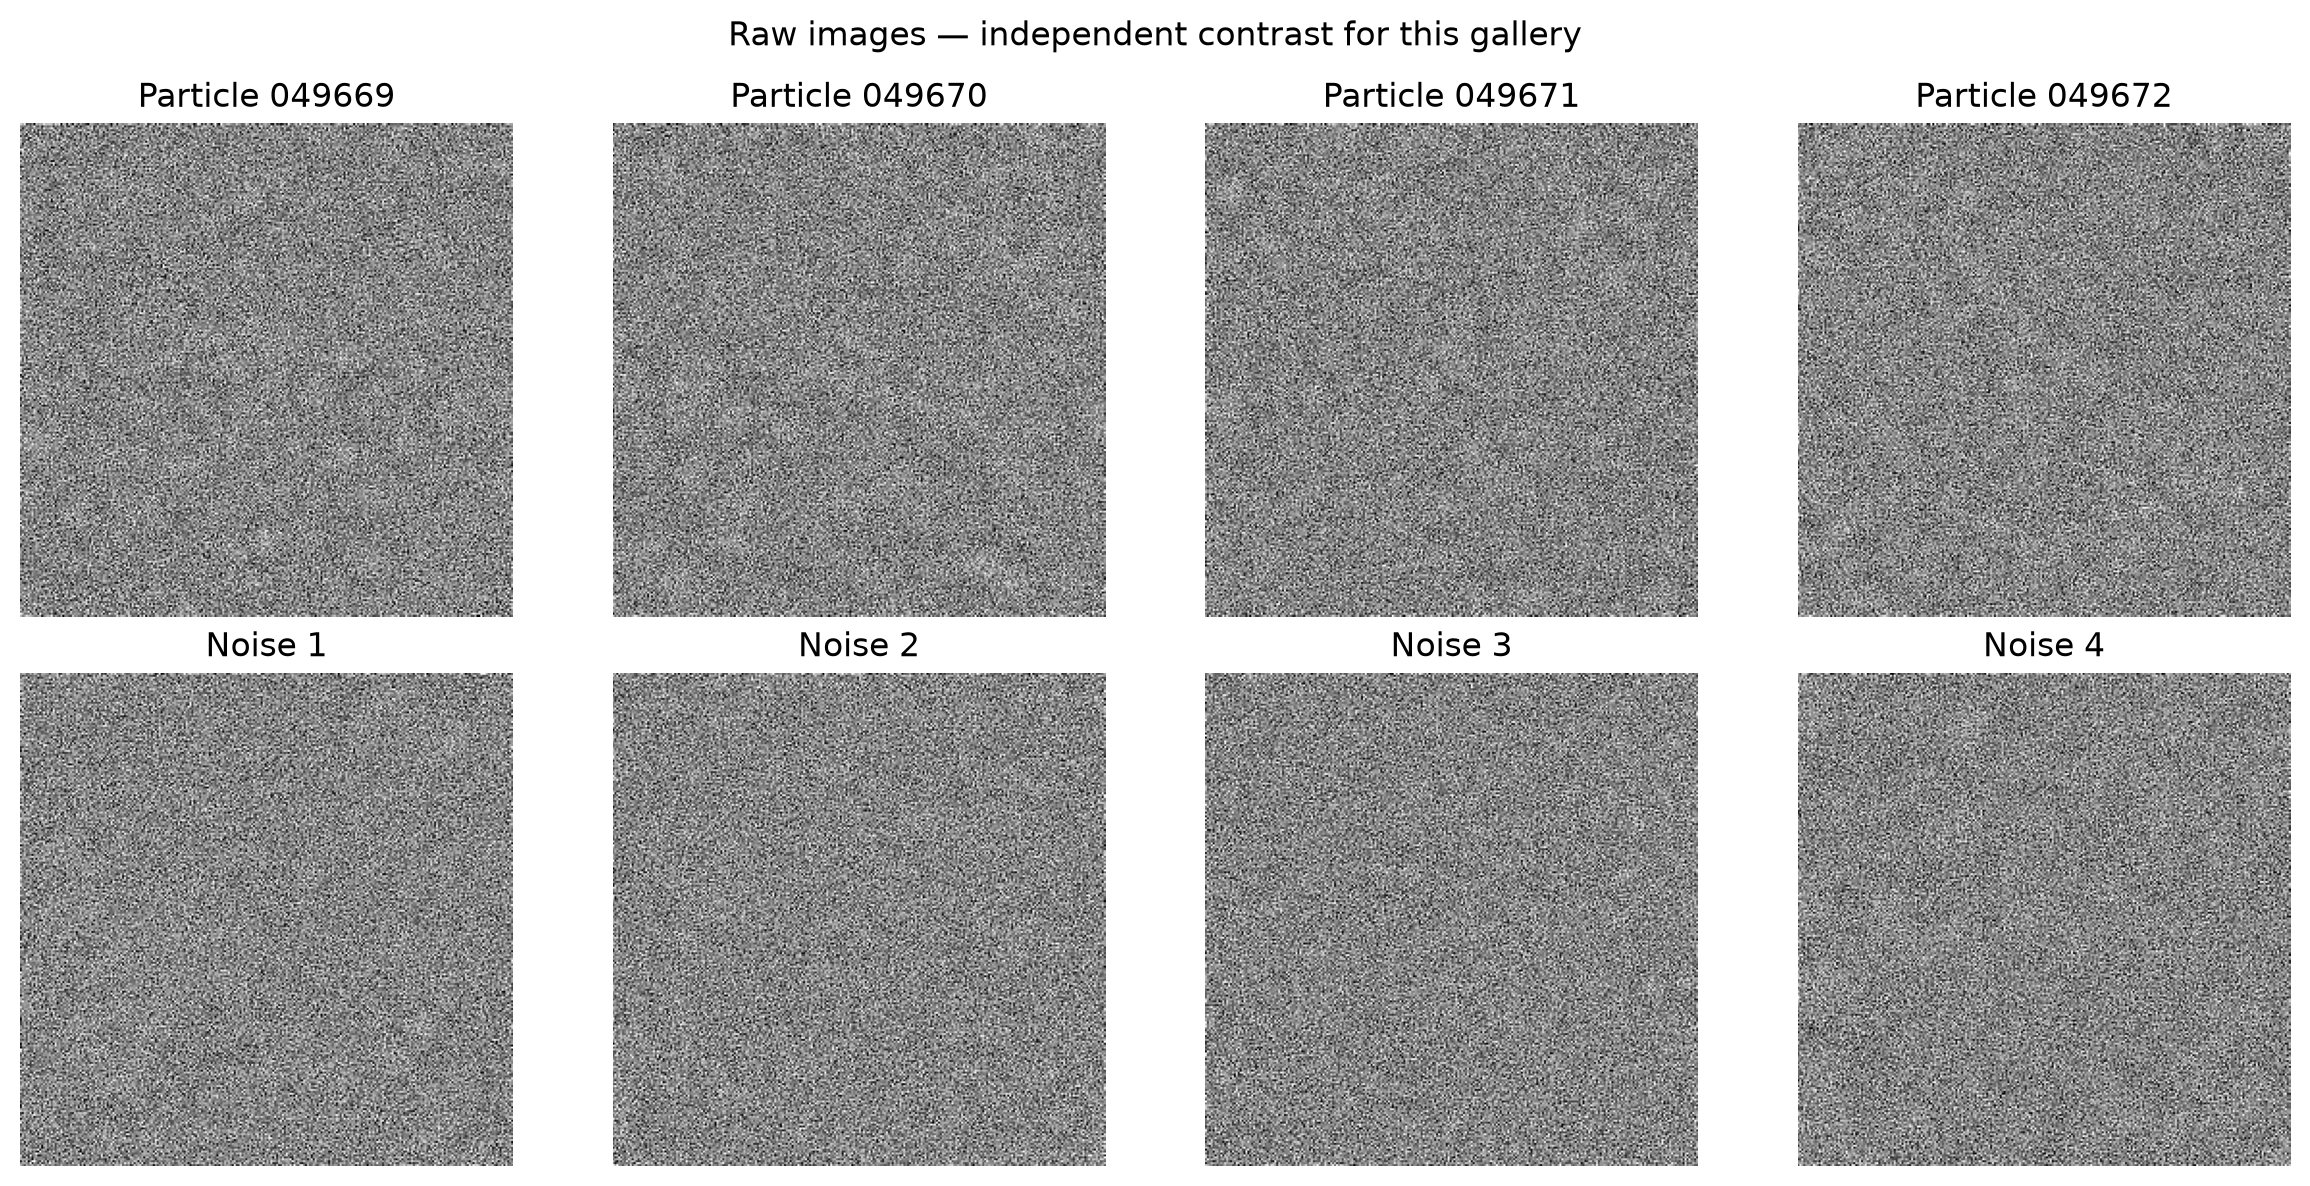

In [2]:
show_raw(particle_images, noise_images, particle_names, count=preview_count)


# 2. CWF

## 2.1. Method code

Fit a CTF-aware covariance Wiener filter on the particles, using the empty stack for noise statistics. Shared Fourier downsampling, reflection padding, and noise whitening precede fitting; crop the output back to the full square. The default 64 × 64 working output keeps this experiment practical; set `cwf_resolution = 128` for a larger output. CTF grouping and angular averaging are approximations. No particle alignment is applied.

Process noise through the **same fitted particle covariance**, without refitting on empty images. Noise has no STAR CTF metadata, so its control images are explicitly assigned the selected particle CTFs in cyclic order. This is a model-response control, not known physical CTF information for the empty images. These noise images also estimate the noise spectrum, so the control is not held out. A particle mean can appear in the noise output; smoothness is not a quality score.


In [5]:
from latent_methods import denoise_selected_cwf

cwf_resolution = 128
cwf_batch_size = 32
cwf_threads = 2
cwf_max_ctf_groups = 32
cwf_padding_factor = 1.6
cwf_memory_budget_gb = 8.0


## 2.2. Execution
The separate save cell below writes the full particle/noise outputs and matched inputs to a new `outputs/cwf_saved_*/cwf_result.npz`. If `cwf_result` is already in memory, run **only the save cell**; no CWF rerun is needed. Each save creates a new folder.


In [6]:
# Release previous processed outputs before rerunning.
globals().pop("cwf_result", None)
started = perf_counter()
with threadpool_limits(limits=cwf_threads):
    cwf_result = denoise_selected_cwf(
        particle_images, particle_metadata, optics, noise_path=noise_path,
        noise_images=noise_images, resolution=cwf_resolution,
        batch_size=cwf_batch_size, max_ctf_groups=cwf_max_ctf_groups,
        padding_factor=cwf_padding_factor, memory_budget_gb=cwf_memory_budget_gb,
    )
print(f"CWF particles: {cwf_result['denoised'].shape}; noise: {cwf_result['noise_denoised'].shape}")
print(f"Elapsed: {perf_counter() - started:.1f} s; pixel size: {cwf_result['pixel_size_angstrom']:.2f} Å")


/Users/xuelongfan/Local work/2026HT ML4LS/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Preparing basis for 2000 particles and 32 CTF groups...
Estimated working memory: 2.59 GiB / 8.00 GiB budget
Maximum CTF grouping differences: mean defocus 580.0 Å; half-astigmatism 91.8 Å
CWF workspace: 206 × 206; output: 128 × 128
Fitting covariance and denoising in batches...


/Users/xuelongfan/Local work/2026HT ML4LS/.venv/lib/python3.13/site-packages/numpy/lib/_index_tricks_impl.py:923: ComplexWarning: Casting complex values to real discards the imaginary part
  a.flat[:end:step] = val
/Users/xuelongfan/Local work/2026HT ML4LS/.venv/lib/python3.13/site-packages/aspire/operators/blk_diag_matrix.py:133: ComplexWarning: Casting complex values to real discards the imaginary part
  self.data[key] = value.astype(self.dtype, copy=False)


2026-10-14 15:55:05,781 WARNING [aspire.covariance.covar2d] Left side b after removing noise in Batched Cov2D is not positive semidefinite.
2026-10-14 15:55:07,152 WARNING [aspire.covariance.covar2d] Covariance matrix in Batched Cov2D is not positive semidefinite.
CWF particles: (2000, 128, 128); noise: (1314, 128, 128)
Elapsed: 73.5 s; pixel size: 2.60 Å


In [7]:
# Save existing CWF results without rerunning the computation above.
from cwf_storage import save_cwf_result

cwf_saved_directory = save_cwf_result(cwf_result, project_root / "outputs")
print(f"Saved full CWF results: {cwf_saved_directory / 'cwf_result.npz'}")


Saved full CWF results: /Users/xuelongfan/Local work/2026HT ML4LS/outputs/cwf_saved_9iam11tf/cwf_result.npz


## 2.3. Display results

Each raw/processed pair uses the same image and contrast limits. CWF's input column is the raw image **Fourier-downsampled to the output grid, with the shared noise background removed**. The right column is a CTF-corrected estimate, so it need not have the same contrast as the observation. Particle order remains the STAR order; noise order remains the stack order.

In the checked default run, ASPIRE reported non-positive-semidefinite covariance estimates, and the noise controls also acquired visible structure. Treat these CWF outputs as exploratory estimates, not validated particle recovery.


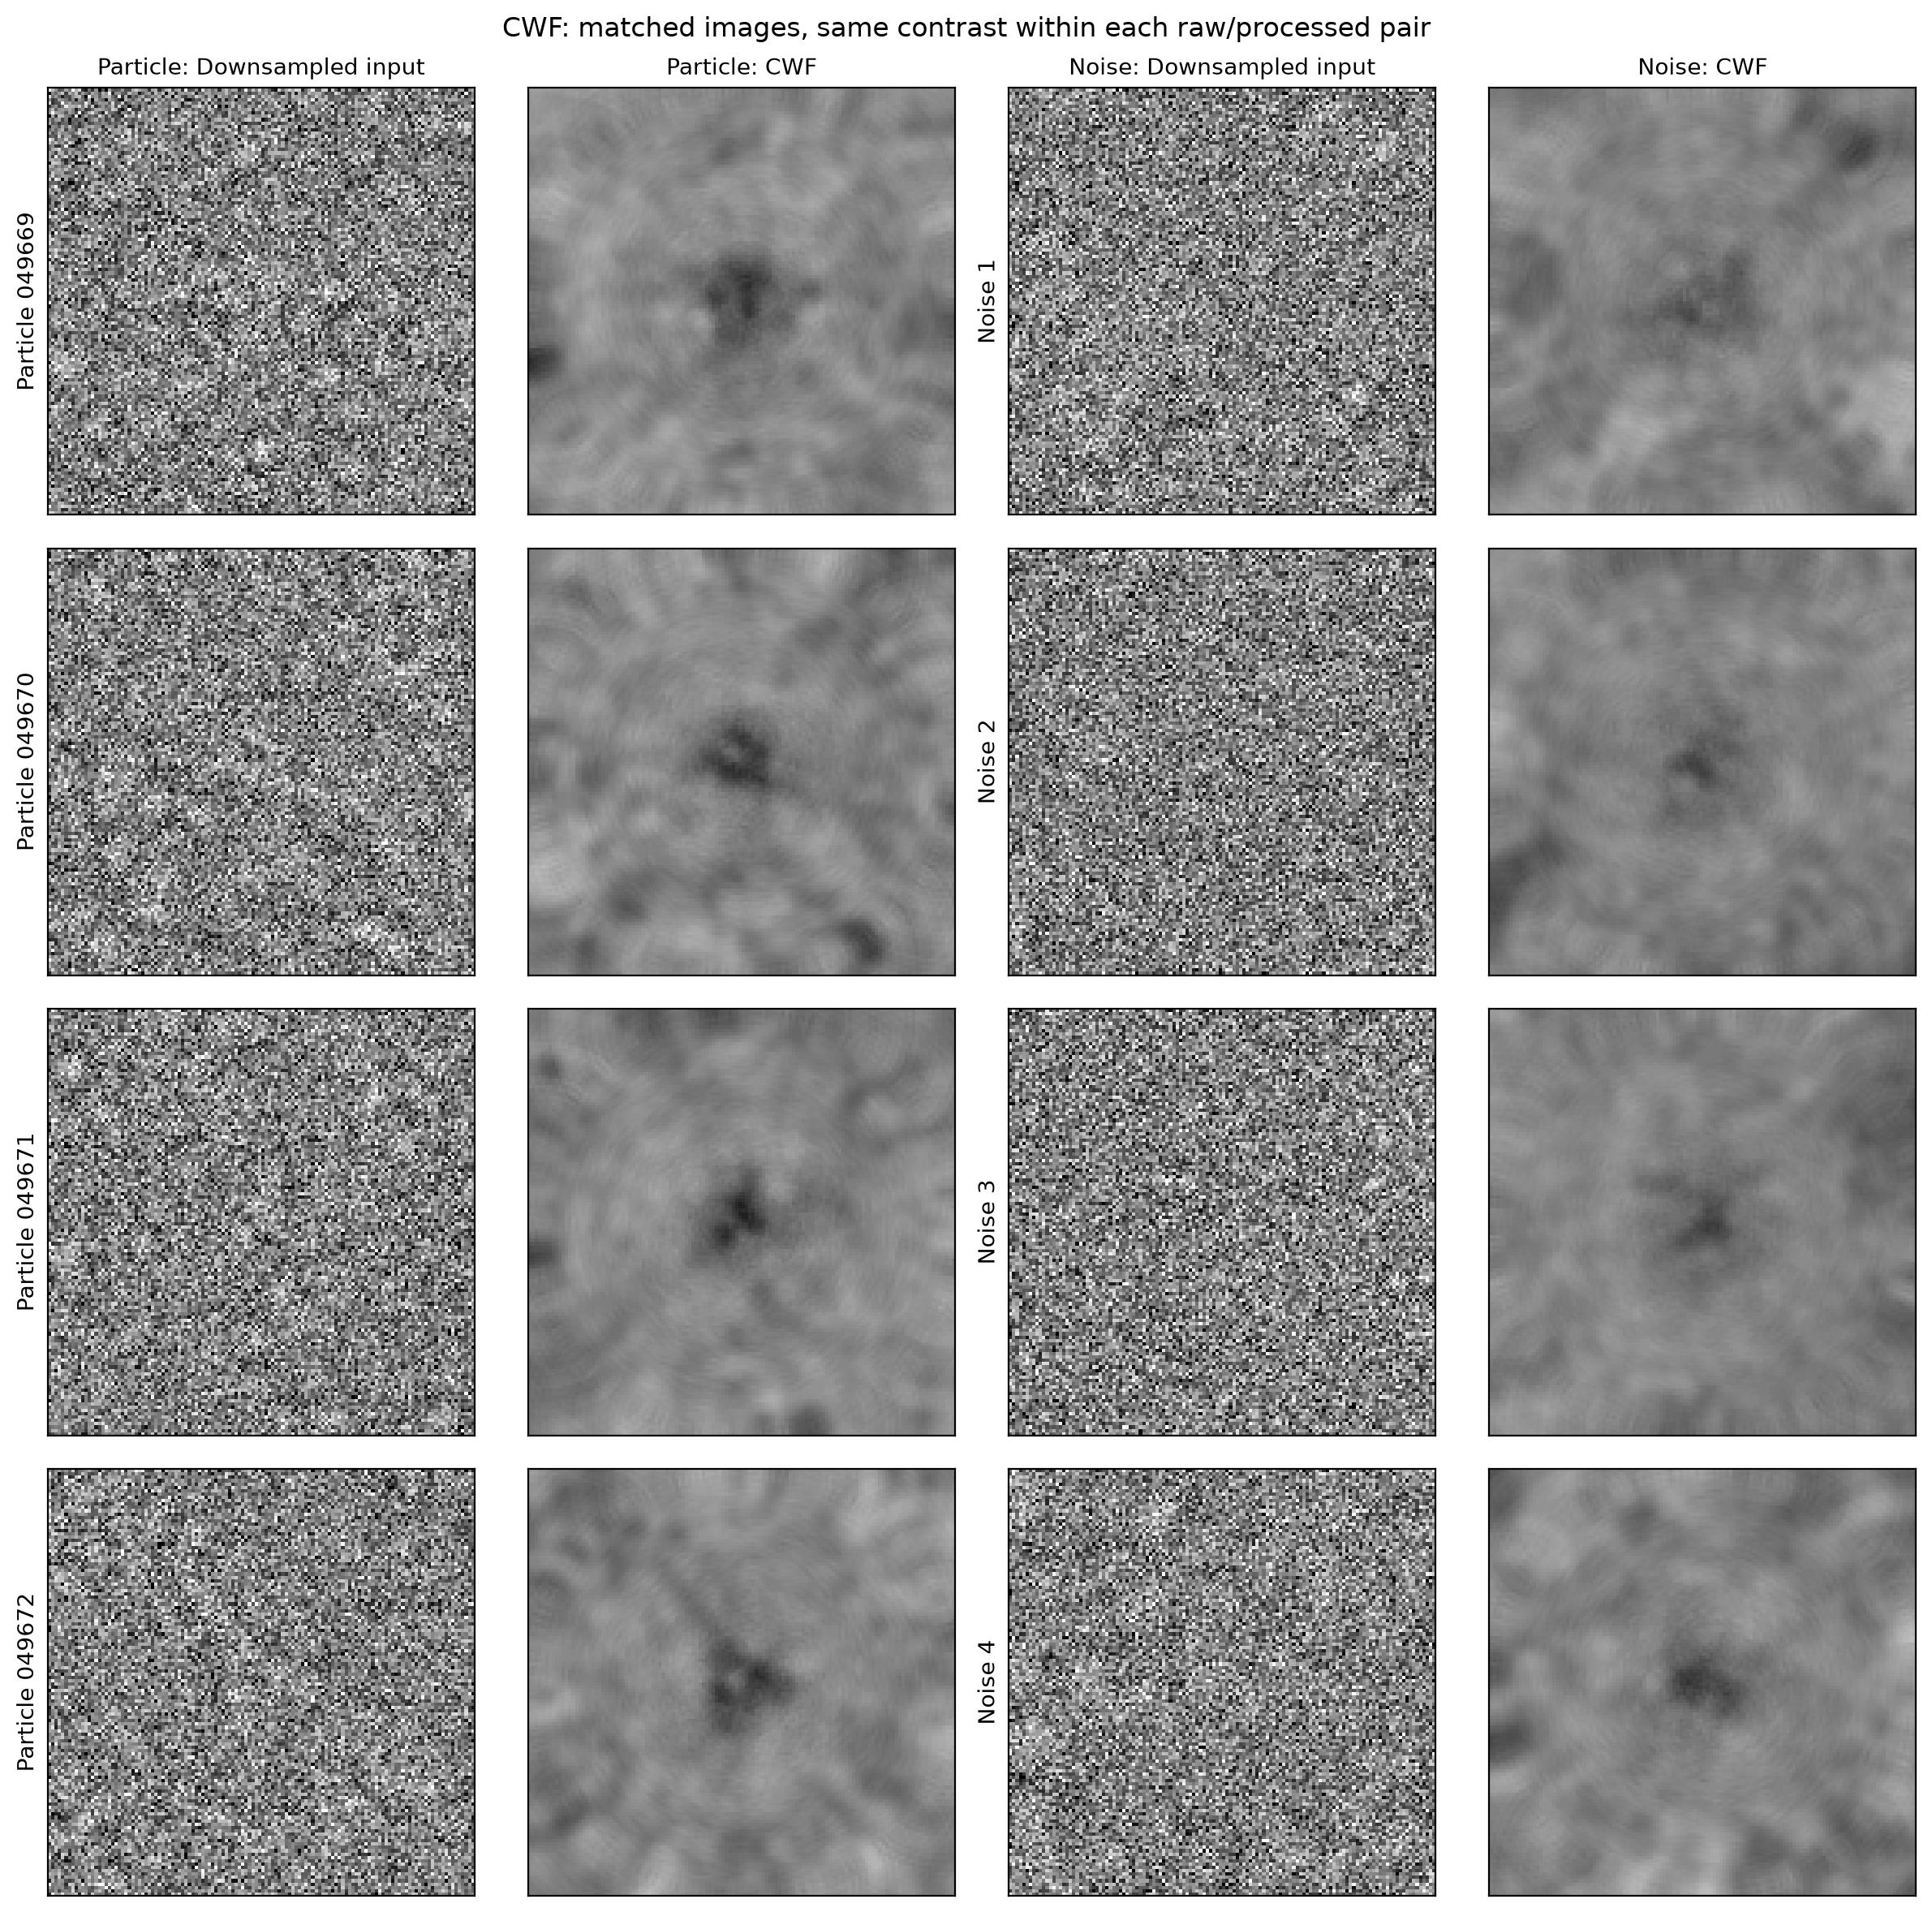

In [8]:
show_pairs(
    cwf_result["input"], cwf_result["denoised"],
    cwf_result["noise_input"], cwf_result["noise_denoised"],
    particle_names, method="CWF", count=preview_count,
    input_label="Downsampled input",
)


## 2.4. Keep a centered circle (80-pixel diameter)

Use **128 × 128 CWF outputs**. A radius-40 circle is centered at pixel coordinates `(63.5, 63.5)`, the geometric center of the image. Keep pixels whose centers lie inside or on the circle. The same mask is applied to particles, noise, and their matched downsampled inputs; no resizing or interpolation is used.

`cwf_circle_pixels` contains only the retained pixels, with shape `(number_of_images, number_of_inside_pixels)` for each stack. `cwf_circle_mask` records their positions; NumPy extracts them in row-major order. Outside pixels are hidden in the display, not treated as observations. Original `cwf_result` arrays and section 3's full-image PCA remain unchanged.

If a previous run left 64 × 64 results in memory, rerun sections **2.1 and 2.2** with `cwf_resolution = 128` first. This cell checks the actual array dimensions.

After extraction, the separate save cell writes `cwf_circles.npz` in the same run folder and marks that complete pair as the latest checkpoint. This preserves both processed particle/noise vectors, matched input vectors, the mask, diameter, image names, and pixel size.


In [9]:
import numpy as np
import matplotlib.pyplot as plt

cwf_circle_diameter = 80


def extract_cwf_circle(result, diameter=80):
    """Extract actual interior pixels from matched 128×128 CWF image stacks."""
    keys = ("input", "denoised", "noise_input", "noise_denoised")
    stacks = {}
    for key in keys:
        if result.get(key) is None:
            raise ValueError(f"Missing cwf_result[{key!r}]; rerun section 2.2 with noise images.")
        stack = np.asarray(result[key])
        if stack.ndim != 3 or stack.shape[1:] != (128, 128) or len(stack) == 0:
            raise ValueError(
                f"cwf_result[{key!r}] has shape {stack.shape}; expected (N, 128, 128). "
                "Rerun sections 2.1 and 2.2 with cwf_resolution = 128."
            )
        stacks[key] = stack
    if (stacks["input"].shape != stacks["denoised"].shape
            or stacks["noise_input"].shape != stacks["noise_denoised"].shape):
        raise ValueError("Each input stack must have the same shape as its processed stack.")
    if not np.isfinite(diameter) or not 0 < diameter <= 128:
        raise ValueError("Circle diameter must be positive and at most 128 pixels.")
    yy, xx = np.ogrid[:128, :128]
    mask = (xx - 63.5)**2 + (yy - 63.5)**2 <= (diameter / 2)**2
    if not mask.any():
        raise ValueError("Circle is too small to contain any pixel centers.")
    pixels = {key: stack[:, mask] for key, stack in stacks.items()}
    if any(not np.isfinite(values).all() for values in pixels.values()):
        raise ValueError("Non-finite pixels inside the circle.")
    return mask, pixels


if "cwf_result" not in globals():
    raise RuntimeError("Run section 2.2 first to create cwf_result.")
cwf_circle_mask, cwf_circle_pixels = extract_cwf_circle(cwf_result, cwf_circle_diameter)
print(f"Circle: diameter {cwf_circle_diameter} pixels; retained pixels per image: {cwf_circle_mask.sum()}")
print(f"Particles: {cwf_circle_pixels['denoised'].shape}; noise: {cwf_circle_pixels['noise_denoised'].shape}")


Circle: diameter 80 pixels; retained pixels per image: 5024
Particles: (2000, 5024); noise: (1314, 5024)


In [10]:
# Save the extracted circles; the full checkpoint from 2.2 must already exist.
from cwf_storage import save_cwf_circles

cwf_circle_file = save_cwf_circles(cwf_result, cwf_circle_pixels, cwf_circle_mask, cwf_circle_diameter)
print(f"Saved cropped particles and noise: {cwf_circle_file}")
print("Section 3 can now run in a fresh kernel using these saved outputs.")


Saved cropped particles and noise: /Users/xuelongfan/Local work/2026HT ML4LS/outputs/cwf_saved_9iam11tf/cwf_circles.npz
Section 3 can now run in a fresh kernel using these saved outputs.


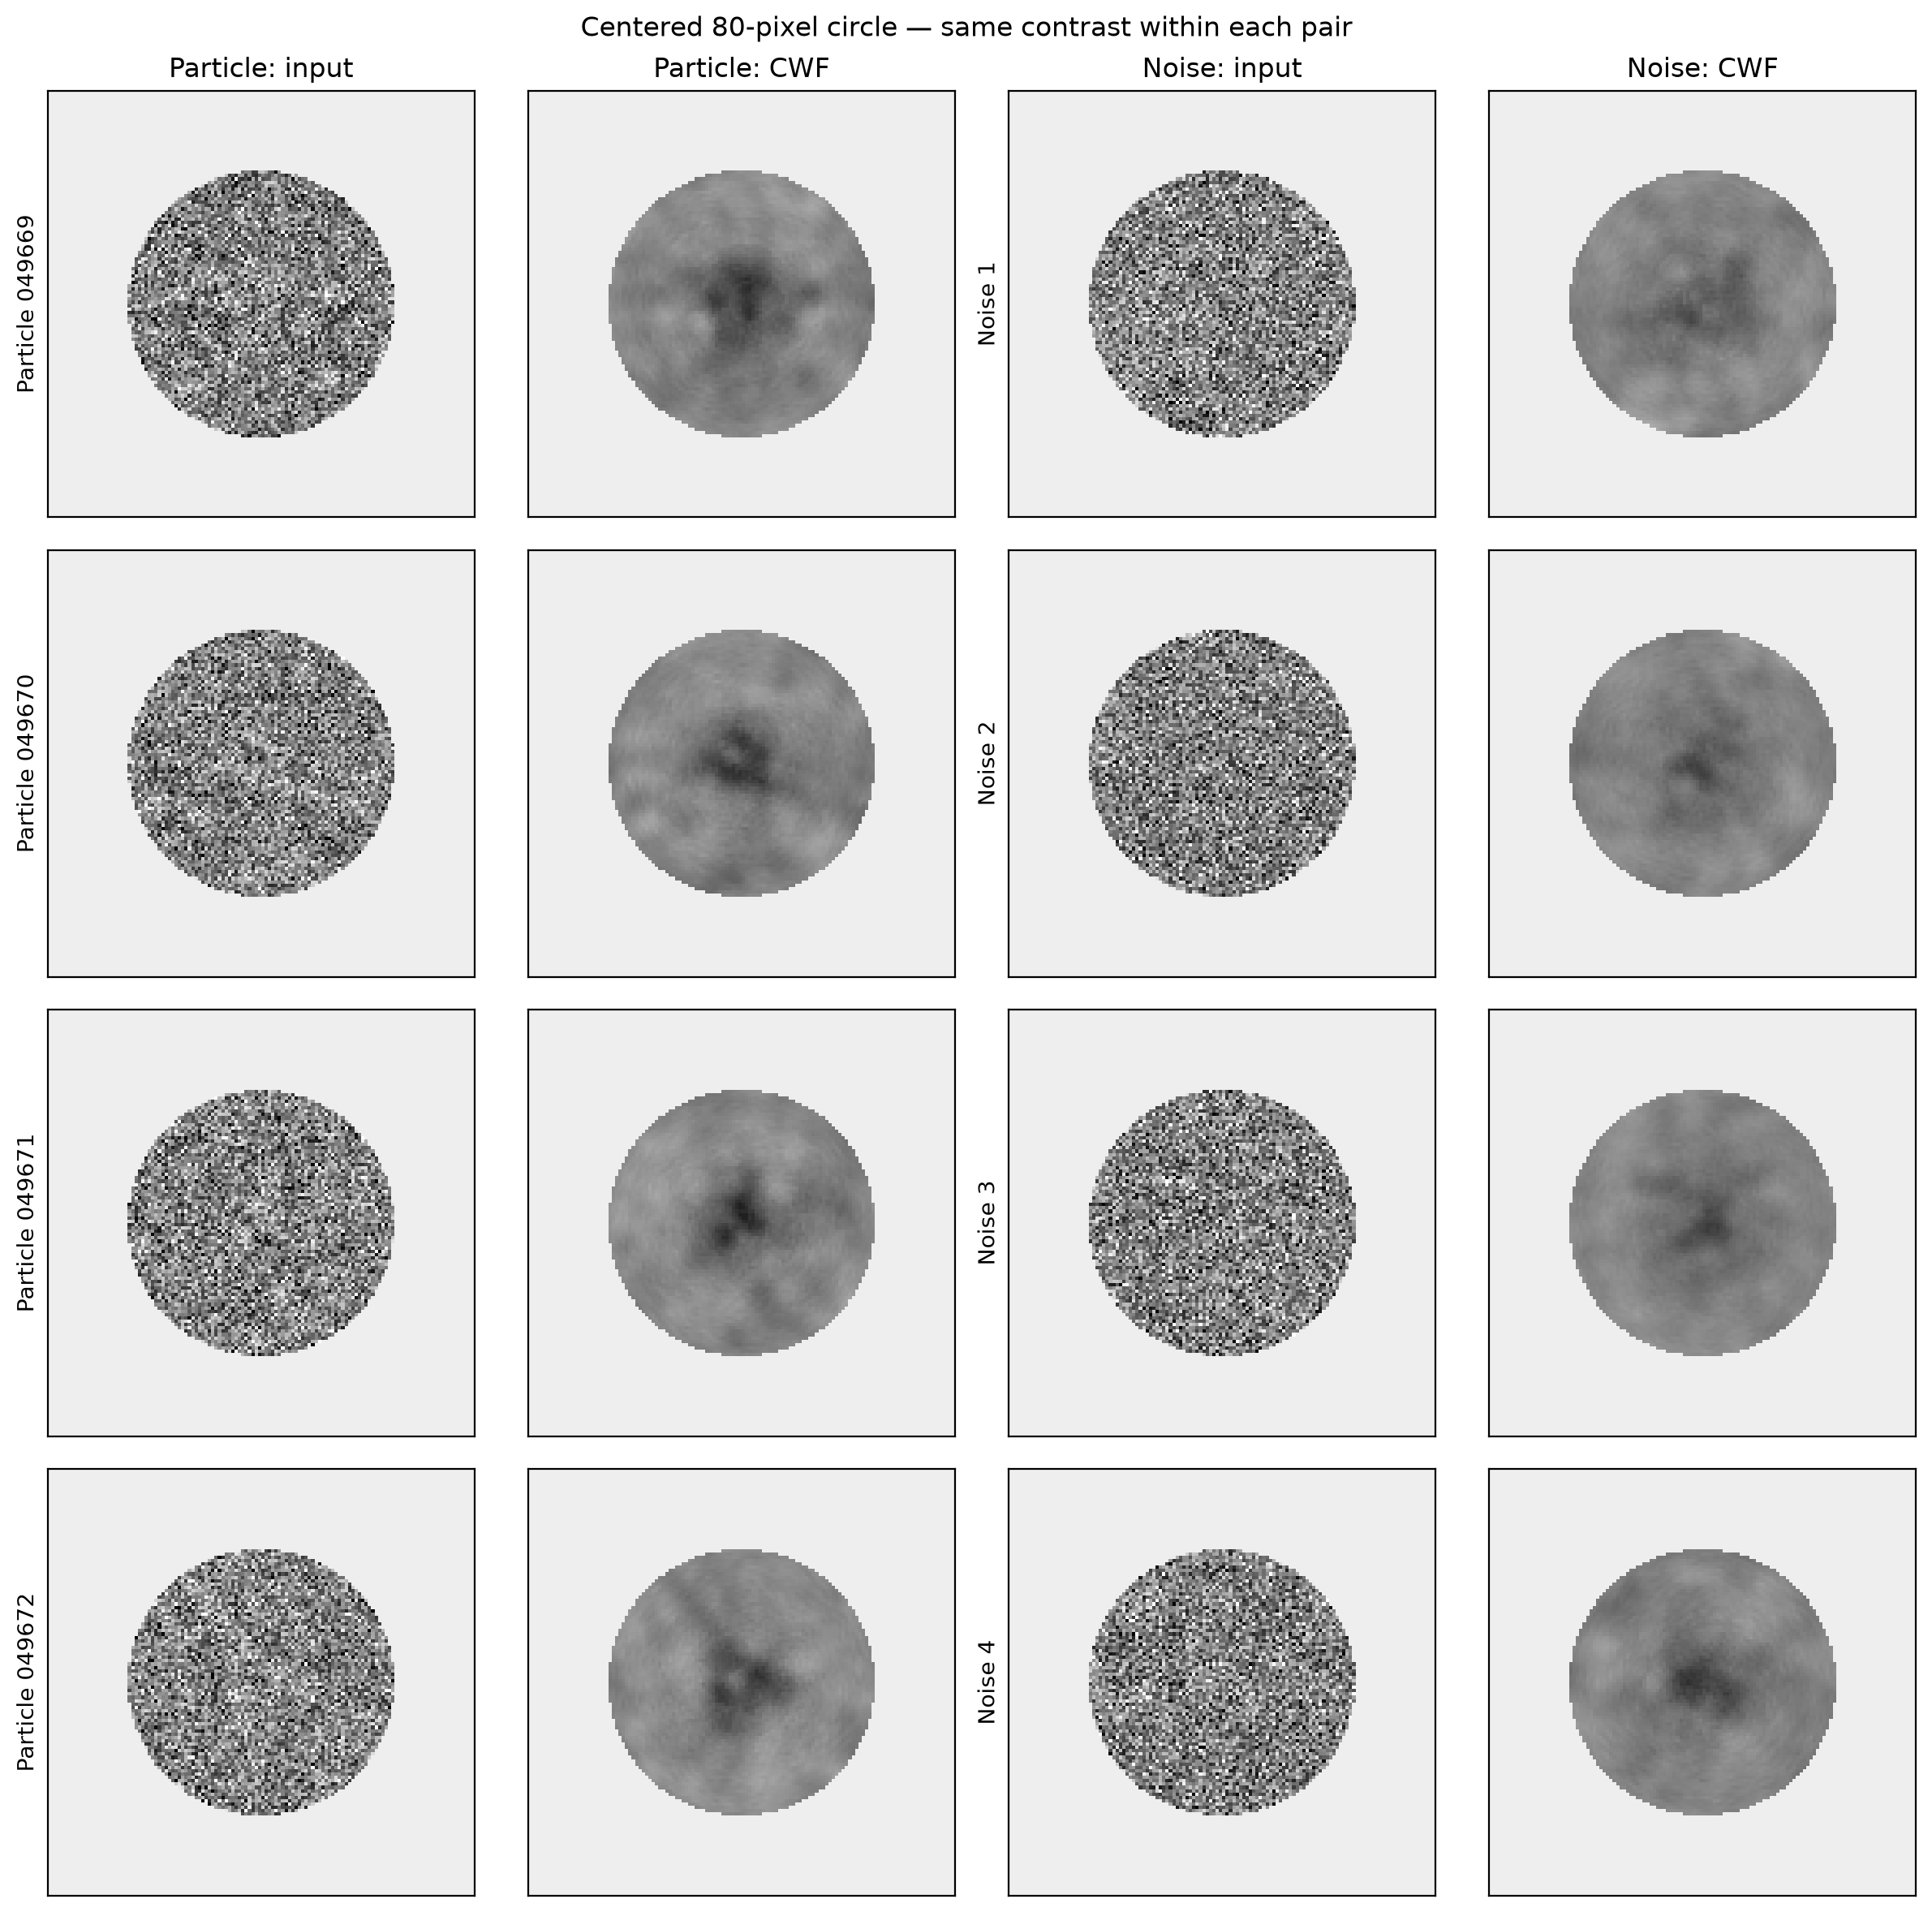

In [11]:
# Display the actual extracted pixels in their original locations.
cwf_circle_preview_count = min(preview_count, len(cwf_circle_pixels["denoised"]),
                               len(cwf_circle_pixels["noise_denoised"]))
if cwf_circle_preview_count < 1:
    raise ValueError("preview_count must be positive.")
cwf_circle_cmap = plt.get_cmap("gray").copy()
cwf_circle_cmap.set_bad("#eeeeee")
fig, axes = plt.subplots(cwf_circle_preview_count, 4,
                         figsize=(12, 3*cwf_circle_preview_count), squeeze=False)
for row in range(cwf_circle_preview_count):
    for col, input_key, output_key in ((0, "input", "denoised"),
                                       (2, "noise_input", "noise_denoised")):
        low, high = np.percentile(cwf_circle_pixels[input_key][row], [1, 99])
        for ax, key in zip(axes[row, col:col+2], (input_key, output_key)):
            image = np.zeros((128, 128), dtype=cwf_circle_pixels[key].dtype)
            image[cwf_circle_mask] = cwf_circle_pixels[key][row]
            ax.imshow(np.ma.array(image, mask=~cwf_circle_mask),
                      cmap=cwf_circle_cmap, vmin=low, vmax=high, interpolation="nearest")
            ax.set_xticks([]); ax.set_yticks([])
    reference = str(cwf_result["image_names"][row]).split("@", 1)[0]
    axes[row, 0].set_ylabel(f"Particle {reference}")
    axes[row, 2].set_ylabel(f"Noise {row+1}")
for ax, title in zip(axes[0], ("Particle: input", "Particle: CWF", "Noise: input", "Noise: CWF")):
    ax.set_title(title)
fig.suptitle(f"Centered {cwf_circle_diameter}-pixel circle — same contrast within each pair")
fig.tight_layout(); plt.show(); plt.close(fig)


# 3. PCA of cropped CWF particles and noise

## 3.1. Method code

Run the save cells in **2.2 and 2.4 once**. Afterwards, section 3 runs directly in a fresh kernel: it reads the full-result checkpoint metadata and cropped-circle checkpoint, without rerunning sections 1 or 2. It uses `cwf_circle_pixels["denoised"]` and `cwf_circle_pixels["noise_denoised"]`. Both groups are **CWF-processed**, at the same pixel size. The noise group is the control processed with the fitted particle covariance and assigned particle CTFs, not raw noise.

Each cropped image is already a vector of **5,024 interior pixels** for the 80-pixel-diameter circle. Concatenate particle and noise vectors as separate rows, then fit **one shared PCA**. Only pixels inside the common circle enter PCA; outside pixels and display backgrounds are excluded. PCA centers each pixel across the combined dataset; there is no per-image normalization, group-mean subtraction, or ICA. Source labels only color the plots.

These are exploratory, in-sample coordinates of CWF outputs. Separation could reflect processing or acquisition differences; overlap or separation does not establish particle identity or successful denoising. CWF can impose structure on noise-only images.


In [12]:
from pathlib import Path
import sys

# Locate the saved data without importing or loading the raw image stacks.
_here = Path.cwd().resolve()
_saved_project = next((p for p in (_here, *_here.parents) if (p / "LatentSpace_data").is_dir()), None)
if _saved_project is None:
    raise FileNotFoundError("Cannot find the project data directory")
if str(_saved_project / "LatentSpace") not in sys.path:
    sys.path.insert(0, str(_saved_project / "LatentSpace"))
from cwf_storage import load_cwf_circles

cwf_saved_directory = None  # Latest complete pair; or set "cwf_saved_..." to choose a run.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits
from IPython.display import display

cwf_pca_components = 20
cwf_pca_seed = 0
cwf_pca_threads = 2


def embed_cwf_circles(circle_pixels, names, n_components=20, seed=0, threads=2):
    """Fit shared PCA on circle-interior vectors, preserving image order."""
    particles = np.asarray(circle_pixels["denoised"])
    noise_value = circle_pixels.get("noise_denoised")
    if noise_value is None:
        raise ValueError("Cropped noise pixels are missing; run subsection 2.4.")
    noise = np.asarray(noise_value)
    if (particles.ndim != 2 or noise.ndim != 2 or particles.shape[1:] != noise.shape[1:]
            or len(particles) == 0 or len(noise) == 0):
        raise ValueError("Need nonempty particle/noise matrices with the same number of circle pixels.")
    if not np.isfinite(particles).all() or not np.isfinite(noise).all():
        raise ValueError("CWF images contain non-finite pixels.")
    if len(names) != len(particles):
        raise ValueError("Particle names do not match the CWF image count.")
    # X is the combined pixel-vector representation; rows remain particle-first.
    X = np.concatenate((particles, noise), axis=0).astype(np.float32, copy=False)
    if not isinstance(n_components, (int, np.integer)) or not 3 <= n_components < min(X.shape):
        raise ValueError("Choose >= 3 components, below both sample and pixel counts.")
    with threadpool_limits(limits=threads):
        model = PCA(n_components=n_components, svd_solver="randomized", random_state=seed)
        scores = model.fit_transform(X)
    if not np.isfinite(model.explained_variance_ratio_).all() or model.explained_variance_[0] <= 0:
        raise ValueError("CWF outputs have no finite variation for PCA.")
    metadata = pd.DataFrame({
        "source": ["particle"] * len(particles) + ["noise"] * len(noise),
        "source_row_1based": np.r_[np.arange(1, len(particles)+1), np.arange(1, len(noise)+1)],
        "image_name": list(names) + [f"{i+1:06d}@noise_restacked.mrc" for i in range(len(noise))],
    })
    for j in range(n_components):
        metadata[f"PC{j+1}"] = scores[:,j]
    return model, scores, metadata, X.shape


## 3.2. Execution

`cwf_pca_embedding` contains one row per image; `cwf_pca_table` keeps source labels and image names aligned with those rows. Component count is configurable above.


In [13]:
cwf_circle_pixels, cwf_circle_mask, cwf_saved_names, cwf_circle_diameter, cwf_loaded_directory = load_cwf_circles(
    _saved_project / "outputs", directory=cwf_saved_directory,
)
print(f"Loaded full-result metadata and circle pixels from: {cwf_loaded_directory}")
cwf_pca, cwf_pca_embedding, cwf_pca_table, cwf_pca_input_shape = embed_cwf_circles(
    cwf_circle_pixels, cwf_saved_names, n_components=cwf_pca_components,
    seed=cwf_pca_seed, threads=cwf_pca_threads,
)
print(f"Circle-pixel input: {cwf_pca_input_shape}; PCA embedding: {cwf_pca_embedding.shape}")
print(f"Variance retained by {cwf_pca_components} PCs: {cwf_pca.explained_variance_ratio_.sum():.2%}")
display(cwf_pca_table.groupby("source", sort=False).size().rename("images").to_frame())
display(cwf_pca_table[["source", "source_row_1based", "image_name", "PC1", "PC2", "PC3"]].groupby("source", sort=False).head(3))


Loaded full-result metadata and circle pixels from: /Users/xuelongfan/Local work/2026HT ML4LS/outputs/cwf_saved_9iam11tf
Circle-pixel input: (3314, 5024); PCA embedding: (3314, 20)
Variance retained by 20 PCs: 51.71%


,images
source,
particle,2000
noise,1314


,source,source_row_1based,image_name,PC1,PC2,PC3
0,particle,1,049669@J598/restack/batch_0_restacked.mrc,-0.642754,0.703743,-0.613889
1,particle,2,049670@J598/restack/batch_0_restacked.mrc,-1.118508,0.656361,0.097247
2,particle,3,049671@J598/restack/batch_0_restacked.mrc,-1.318763,0.160503,1.129320
2000,noise,1,000001@noise_restacked.mrc,1.368150,0.108001,-0.014016
2001,noise,2,000002@noise_restacked.mrc,1.101936,-0.099847,0.063733
2002,noise,3,000003@noise_restacked.mrc,0.900910,-0.116038,0.707971


## 3.3. Display results

Each point represents the circle-interior pixels of one CWF-processed image. Plot order is shuffled reproducibly to reduce one group's points covering the other. Axes show each PC's fraction of total combined variance. The cumulative curve describes retained variation, not retained biological signal. The 3D plot adds PC3 to the two-dimensional views.


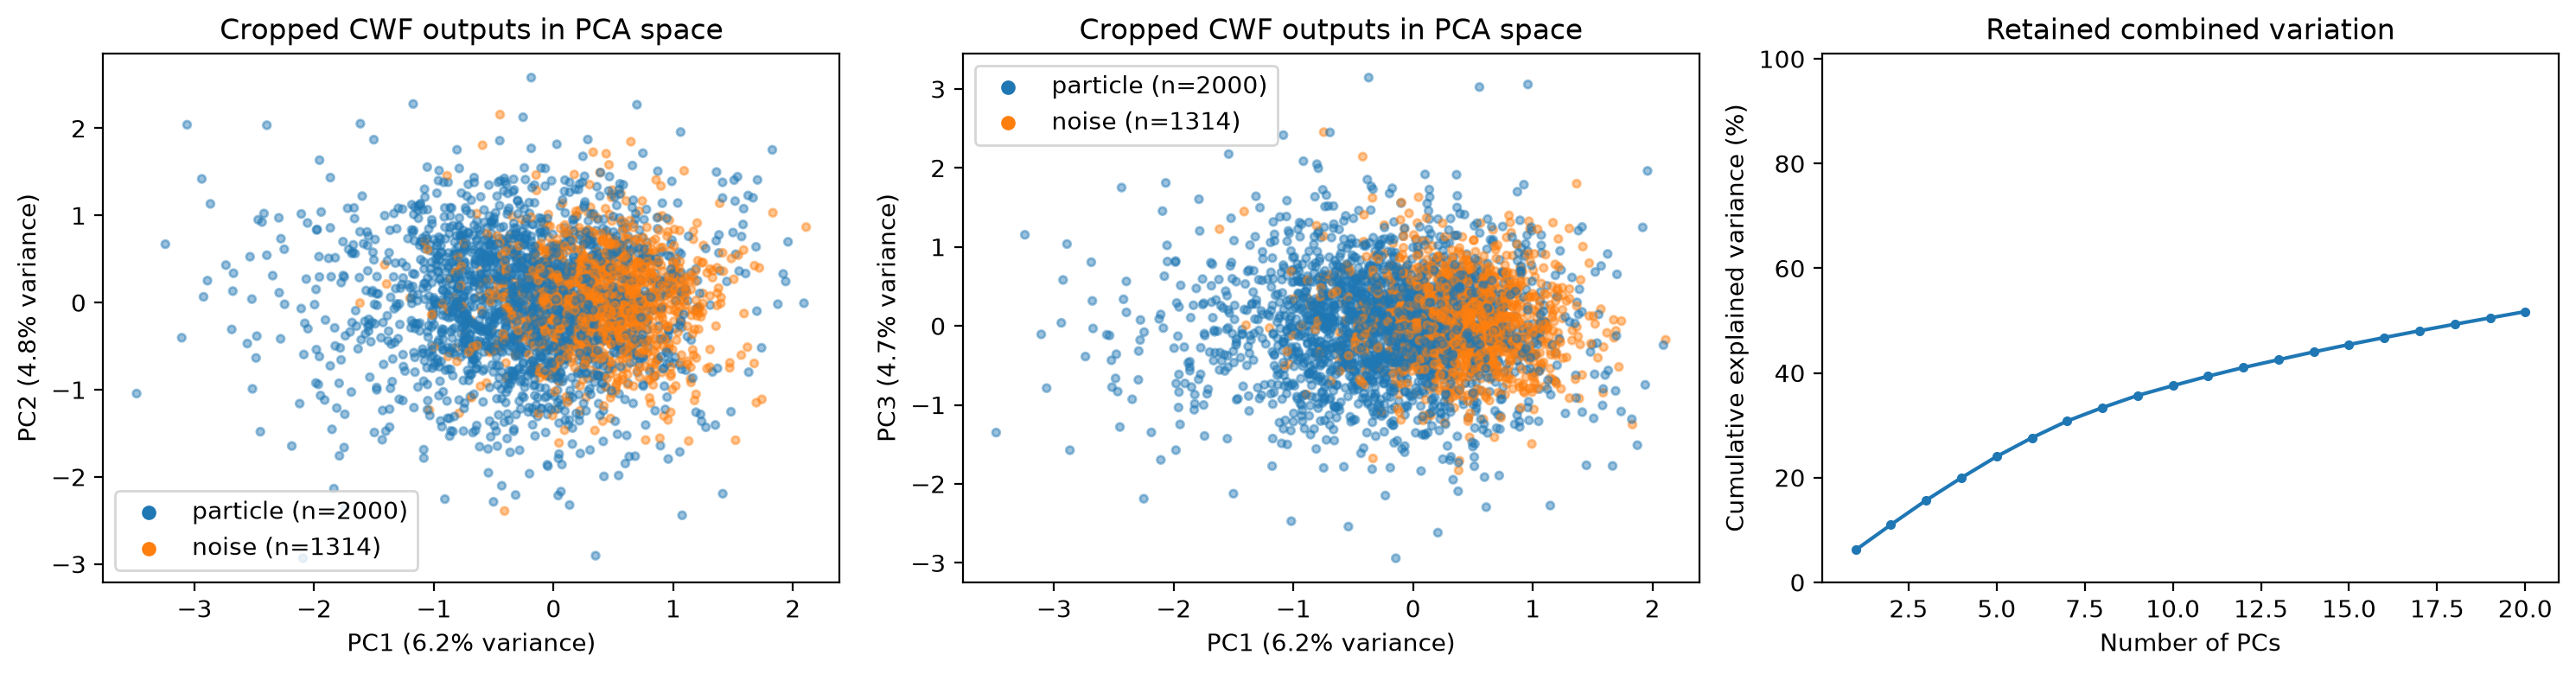

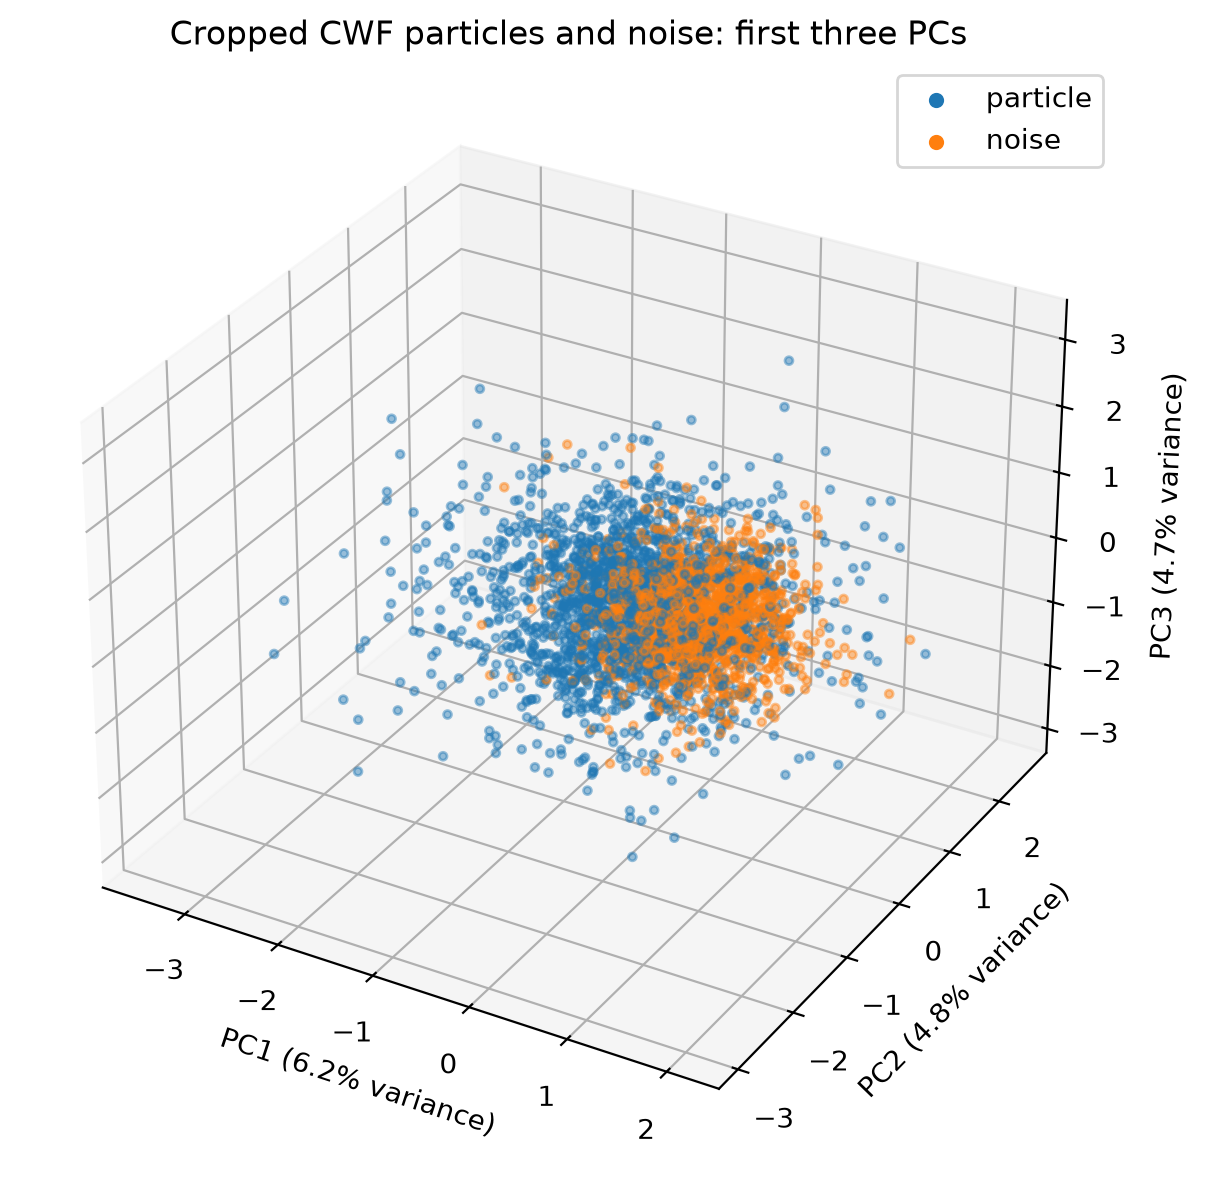

In [14]:
cwf_pca_colors = {"particle": "tab:blue", "noise": "tab:orange"}
cwf_pca_labels = cwf_pca_table["source"].to_numpy()
cwf_pca_order = np.random.default_rng(cwf_pca_seed).permutation(len(cwf_pca_embedding))
cwf_pca_point_colors = [cwf_pca_colors[label] for label in cwf_pca_labels[cwf_pca_order]]
cwf_pca_ratios = cwf_pca.explained_variance_ratio_

def cwf_pc_label(j):
    return f"PC{j+1} ({cwf_pca_ratios[j]:.1%} variance)"

fig, axes = plt.subplots(1,3,figsize=(15,4))
for ax, (a,b) in zip(axes[:2], ((0,1),(0,2))):
    ax.scatter(cwf_pca_embedding[cwf_pca_order,a], cwf_pca_embedding[cwf_pca_order,b],
               c=cwf_pca_point_colors, s=10, alpha=.45, rasterized=True)
    for source, color in cwf_pca_colors.items():
        count=int(np.sum(cwf_pca_labels == source))
        ax.scatter([], [], color=color, label=f"{source} (n={count})", s=25)
    ax.set(xlabel=cwf_pc_label(a), ylabel=cwf_pc_label(b), title="Cropped CWF outputs in PCA space")
    ax.legend()
axes[2].plot(np.arange(1,len(cwf_pca_ratios)+1), np.cumsum(cwf_pca_ratios)*100, "o-", markersize=3)
axes[2].set(xlabel="Number of PCs", ylabel="Cumulative explained variance (%)", title="Retained combined variation", ylim=(0,101))
fig.tight_layout(); plt.show(); plt.close(fig)

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection="3d")
z = cwf_pca_embedding[cwf_pca_order,:3]
ax.scatter(z[:,0],z[:,1],z[:,2], c=cwf_pca_point_colors, s=8, alpha=.45, depthshade=False)
for source,color in cwf_pca_colors.items():
    ax.scatter([],[],[],color=color,label=source)
ax.set(xlabel=cwf_pc_label(0),ylabel=cwf_pc_label(1),zlabel=cwf_pc_label(2),title="Cropped CWF particles and noise: first three PCs")
ax.legend(); fig.tight_layout(); plt.show(); plt.close(fig)
